In [4]:
import requests
import pymupdf 
import fitz
from pathlib import Path

pdf_url = "https://minoritywomyn.org/wp-content/uploads/2025/04/NCCG-GBV-Referral-Directory-pdf.pdf"

pdf_path = Path("nairobi_gbv_referral_directory.pdf")

# Download the PDF
response = requests.get(pdf_url, timeout=30)
response.raise_for_status()

pdf_path.write_bytes(response.content)

# Open and inspect
doc = fitz.open(pdf_path)

print("Pages:", len(doc))
print("File size (KB):", round(pdf_path.stat().st_size / 1024, 2))

print("\nSample extracted text from page 4:")
print(doc[3].get_text()[:1500])

Pages: 13
File size (KB): 4421.83

Sample extracted text from page 4:
—Let’s Make NAIROBI Work— 
Name of Organisation 
Contact Information  
Services Provided  
H/C  
P/S  
E/E  
S/S  
L/S  
Advocates for Social Change (ADSOCK) 
020-5208323 
 
 
 
 
 
Africa Youth Trust/ActionAid Kenya 
SMS "HELP" to 21094 
 
 
 
 
 
African Family Health (AFH)  
020-3755399 / 0722 353777  
 
 
 
 
 
African Network for the Prevention and Protection against Child Abuse 
and Neglect Kenya Chapter (ANPPCAN)  
0202140010 / 020-3861086 
 
 
 
 
 
African Network for the Protection and Prevention of Child Abuse and 
Neglect ANPPCAN  
020-2140010 / 020-2140011 / 
020-2140013 
 
 
 
 
 
African Population and Health Research Center (APHRC) Kenya  
020400 1000 / 0722 205 933 / 
0733 410 102  
 
 
 
 
 
Badlisha Kenya Initiative 
0743-707843 
 
 
 
 
 
Bar Hostess Empowerment and Support Programme (BHESP) 
020 2608944 / 0795196876 / 
0723108010 
 
 
 
 
 
Beacon of Hope 
0723847248/0716642469 
 
 
 
 
 
Binti A

In [5]:
# Inspecting the pdf tables
# Inspect tables on page 4
page = doc[3]

tables = page.find_tables()

print("Number of tables found:", len(tables.tables))

for i, table in enumerate(tables.tables):
    print(f"\nTable {i + 1}")
    print("Rows:", table.row_count)
    print("Columns:", table.col_count)

    # Preview the first five rows
    for row in table.extract()[:5]:
        print(row)

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
Number of tables found: 1

Table 1
Rows: 16
Columns: 7
['Name of Organisation', 'Contact Information', 'Services Provided', None, None, None, None]
[None, None, 'H/C', 'P/S', 'E/E', 'S/S', 'L/S']
['Advocates for Social Change (ADSOCK)', '020-5208323', '', '', '', '', '']
['Africa Youth Trust/ActionAid Kenya', 'SMS "HELP" to 21094', '', '', '', '', '']
['African Family Health (AFH)', '020-3755399 / 0722 353777', '', '', '', '', '']


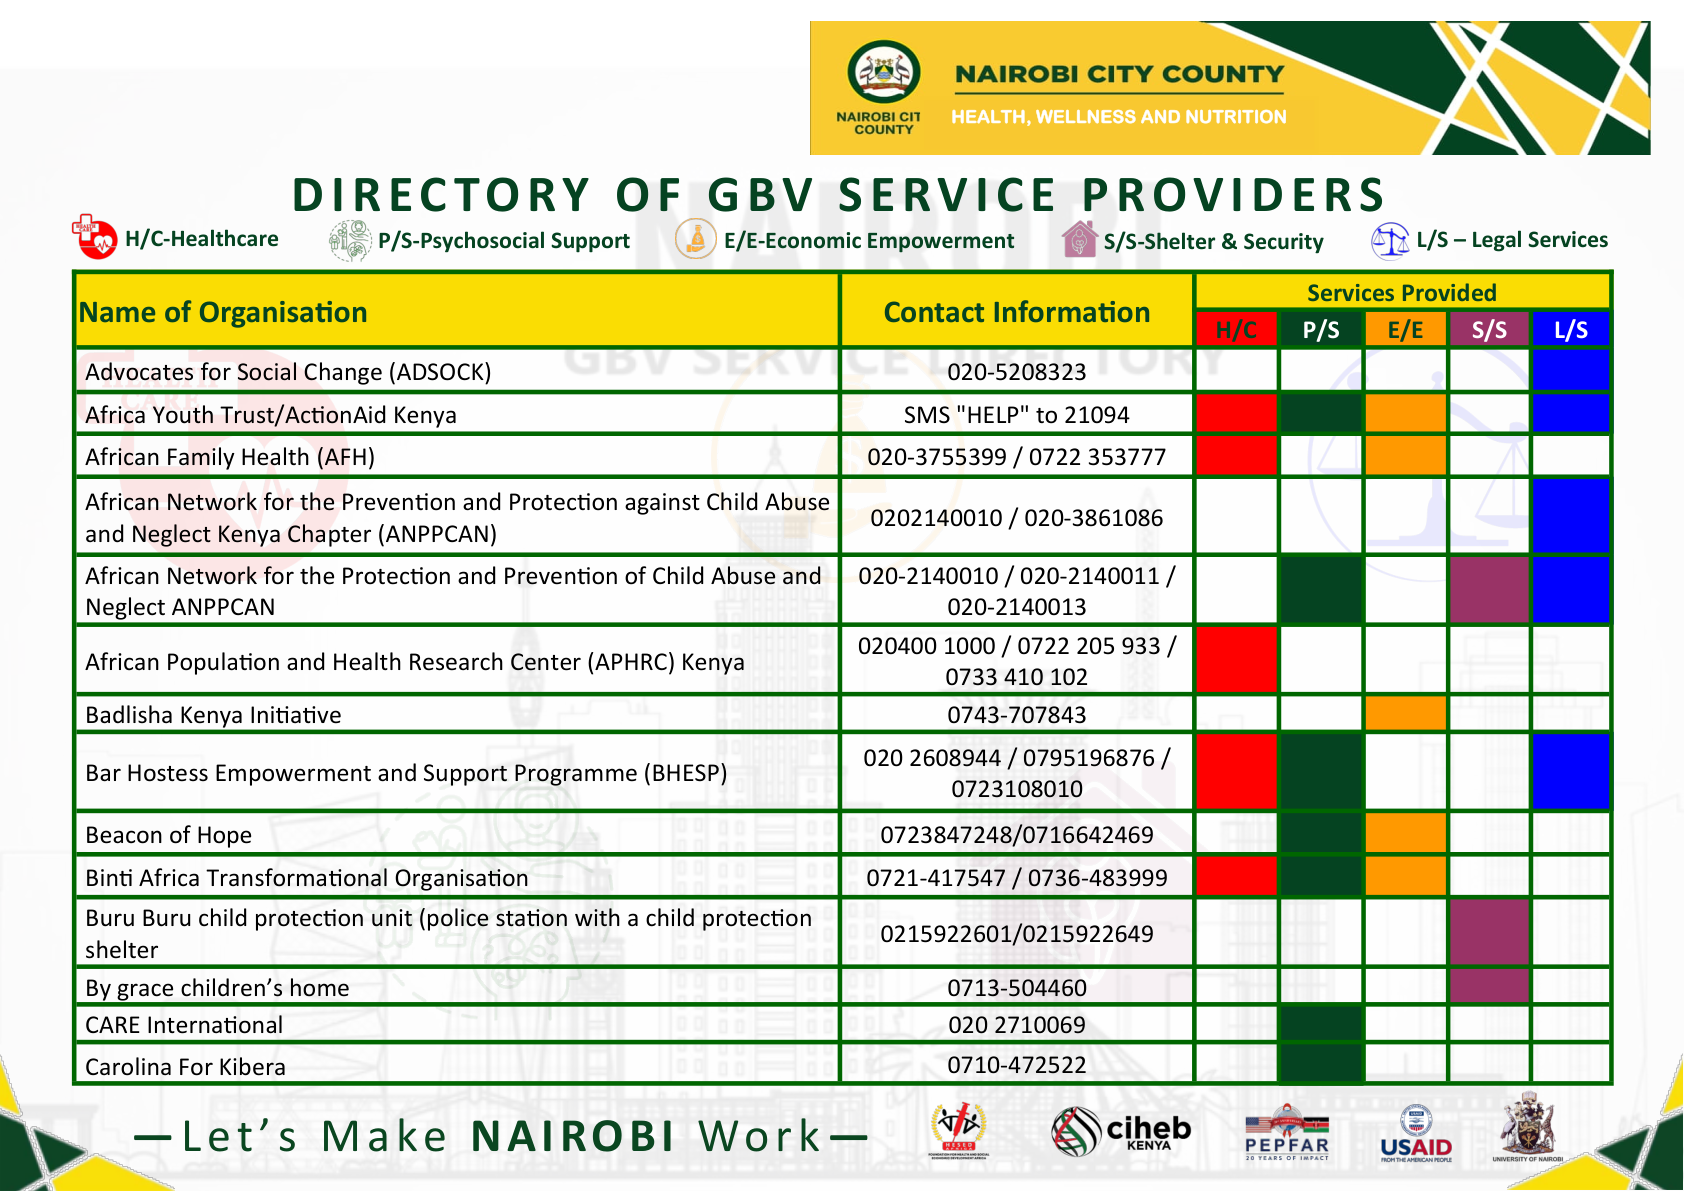

In [6]:
from IPython.display import display, Image

# Render page 4 at higher resolution
page = doc[3]

pix = page.get_pixmap(
    matrix=fitz.Matrix(2, 2),
    alpha=False
)

display(Image(data=pix.tobytes("png")))

In [7]:
# Checking whether the colored cells are detectable
page = doc[3]

drawings = page.get_drawings()

# Extract filled shapes and their colours
filled_shapes = [
    {
        "rect": drawing["rect"],
        "fill": drawing["fill"]
    }
    for drawing in drawings
    if drawing["fill"] is not None
]

print("Number of filled shapes:", len(filled_shapes))

# Preview the first 15
for shape in filled_shapes[:15]:
    print(shape)

Number of filled shapes: 59
{'rect': Rect(35.96099853515625, 134.83700561523438, 419.96099853515625, 173.70001220703125), 'fill': (0.984000027179718, 0.8669999837875366, 0.011800000444054604)}
{'rect': Rect(419.9599914550781, 134.83700561523438, 597.1699829101562, 173.70001220703125), 'fill': (0.984000027179718, 0.8669999837875366, 0.011800000444054604)}
{'rect': Rect(597.1699829101562, 134.83602905273438, 806.8699951171875, 154.83001708984375), 'fill': (0.984000027179718, 0.8669999837875366, 0.011800000444054604)}
{'rect': Rect(597.1799926757812, 154.83102416992188, 639.47998046875, 173.70001220703125), 'fill': (1.0, 0.0, 0.0)}
{'rect': Rect(639.47998046875, 154.83102416992188, 681.7799682617188, 173.70001220703125), 'fill': (0.023499999195337296, 0.2630000114440918, 0.13300000131130219)}
{'rect': Rect(681.77001953125, 154.83102416992188, 724.0700073242188, 173.70001220703125), 'fill': (1.0, 0.6000000238418579, 0.0)}
{'rect': Rect(724.0700073242188, 154.83102416992188, 765.47003173828

In [8]:
# Matching colored cells to organizations
page = doc[3]
table = page.find_tables().tables[0]

services = [
    "Healthcare",
    "Psychosocial Support",
    "Economic Empowerment",
    "Shelter & Security",
    "Legal Services"
]

records = []

for row_index in range(2, table.row_count):

    row = table.extract()[row_index]

    organisation = row[0]
    contact = row[1]

    detected_services = []

    for col_index, service in enumerate(services, start=2):

        cell_rect = table.rows[row_index].cells[col_index]

        if cell_rect is None:
            continue

        cell = fitz.Rect(cell_rect)

        # Find coloured shapes overlapping the cell
        for drawing in page.get_drawings():

            if drawing["fill"] is None:
                continue

            shape = drawing["rect"]

            if (
                cell.intersects(shape)
                and shape.intersects(cell)
            ):
                intersection = cell & shape

                # Require substantial overlap
                if intersection.get_area() / cell.get_area() > 0.8:

                    detected_services.append(service)
                    break

    records.append({
        "organisation": organisation,
        "contact": contact,
        "services": detected_services
    })

# Preview extracted records
for record in records[:5]:
    print(record)

{'organisation': 'Advocates for Social Change (ADSOCK)', 'contact': '020-5208323', 'services': ['Legal Services']}
{'organisation': 'Africa Youth Trust/ActionAid Kenya', 'contact': 'SMS "HELP" to 21094', 'services': ['Healthcare', 'Psychosocial Support', 'Economic Empowerment', 'Legal Services']}
{'organisation': 'African Family Health (AFH)', 'contact': '020-3755399 / 0722 353777', 'services': ['Healthcare', 'Economic Empowerment']}
{'organisation': 'African Network for the Prevention and Protection against Child Abuse\nand Neglect Kenya Chapter (ANPPCAN)', 'contact': '0202140010 / 020-3861086', 'services': ['Legal Services']}
{'organisation': 'African Network for the Protection and Prevention of Child Abuse and\nNeglect ANPPCAN', 'contact': '020-2140010 / 020-2140011 /\n020-2140013', 'services': ['Psychosocial Support', 'Shelter & Security', 'Legal Services']}


Instead of detecting any filled rectangle, we'll check that the rectangle's colour matches the service category. This reduces the risk of incorrectly interpreting background formatting as a service.

In [9]:
# Validating the service colors
service_colours = {
    "Healthcare": (1.0, 0.0, 0.0),
    "Psychosocial Support": (0.0235, 0.263, 0.133),
    "Economic Empowerment": (1.0, 0.6, 0.0),
    "Shelter & Security": (0.6, 0.2, 0.4),
    "Legal Services": (0.0, 0.0, 1.0)
}

def colours_match(actual, expected, tolerance=0.02):
    return (
        actual is not None
        and all(abs(a - e) < tolerance for a, e in zip(actual, expected))
    )


page = doc[3]
table = page.find_tables().tables[0]
rows = table.extract()
drawings = page.get_drawings()

validated_records = []

for row_index in range(2, table.row_count):
    row = rows[row_index]
    detected_services = []

    for col_index, (service, expected_colour) in enumerate(
        service_colours.items(), start=2
    ):
        cell_rect = table.rows[row_index].cells[col_index]

        if cell_rect is None:
            continue

        cell = fitz.Rect(cell_rect)

        for drawing in drawings:
            if not colours_match(drawing["fill"], expected_colour):
                continue

            intersection = cell & drawing["rect"]

            if (
                cell.get_area() > 0
                and intersection.get_area() / cell.get_area() > 0.8
            ):
                detected_services.append(service)
                break

    validated_records.append({
        "organisation": row[0],
        "contact": row[1],
        "services": detected_services
    })

# Compare original and colour-validated results
for original, validated in zip(records, validated_records):
    if original["services"] != validated["services"]:
        print("Difference:", validated["organisation"])
        print("Original:", original["services"])
        print("Validated:", validated["services"])

print("\nValidation completed.")
print("Records checked:", len(validated_records))


Validation completed.
Records checked: 14


All 14 records have no differences between the two extraction methods.

Before extracting all the tables in the pdf, we check whether all pages contain tables and whether they follow the same seven-column structure.

In [10]:
# Inspect tables across all PDF pages
for page_number, page in enumerate(doc, start=1):

    tables = page.find_tables().tables

    print(f"\nPage {page_number}: {len(tables)} table(s)")

    for i, table in enumerate(tables, start=1):
        print(
            f"  Table {i}: "
            f"{table.row_count} rows, "
            f"{table.col_count} columns"
        )

        # Preview the first row to identify the table
        print("  First row:", table.extract()[0])


Page 1: 0 table(s)

Page 2: 0 table(s)

Page 3: 3 table(s)
  Table 1: 14 rows, 3 columns
  First row: ['COUNTY GBV LEADS', None, None]
  Table 2: 13 rows, 3 columns
  First row: ['CHILDREN SERVICES', None, None]
  Table 3: 7 rows, 6 columns
  First row: ['GBV\nHotline', 'Nairobi County', '1508', '', 'Childline Kenya', '116']

Page 4: 1 table(s)
  Table 1: 16 rows, 7 columns
  First row: ['Name of Organisation', 'Contact Information', 'Services Provided', None, None, None, None]

Page 5: 1 table(s)
  Table 1: 16 rows, 7 columns
  First row: ['Name of Organisation', 'Contact Information', 'Services Provided', None, None, None, None]

Page 6: 1 table(s)
  Table 1: 19 rows, 7 columns
  First row: ['Name of Organisation', 'Contact Information', 'Services Provided', None, None, None, None]

Page 7: 1 table(s)
  Table 1: 20 rows, 7 columns
  First row: ['Name of Organisation', 'Contact Information', 'Services Provided', None, None, None, None]

Page 8: 1 table(s)
  Table 1: 16 rows, 7 column

No tables detected in pages 1 and 2, these are introductory pages.

Page 3 will be extracted separately as it contains County GBV leads, children's services and hotlines.

Pages 4-12 contain 7 column tables and will be used to extract various GBV helplines.

Page 13 has no tables and no extraction is needed.

**Extracting all GBV service providers**

In [11]:
import pandas as pd

In [12]:
# Extract service providers from pages 4–12
all_records = []

for page_index in range(3, 12):

    page = doc[page_index]
    table = page.find_tables().tables[0]

    rows = table.extract()
    drawings = page.get_drawings()

    for row_index in range(2, table.row_count):

        row = rows[row_index]

        organisation = row[0]
        contact = row[1]

        if not organisation or not organisation.strip():
            continue

        detected_services = []

        for col_index, (service, expected_colour) in enumerate(
            service_colours.items(), start=2
        ):

            cell_rect = table.rows[row_index].cells[col_index]

            if cell_rect is None:
                continue

            cell = fitz.Rect(cell_rect)

            for drawing in drawings:

                if not colours_match(
                    drawing["fill"], expected_colour
                ):
                    continue

                intersection = cell & drawing["rect"]

                if (
                    cell.get_area() > 0
                    and intersection.get_area() / cell.get_area() > 0.8
                ):
                    detected_services.append(service)
                    break

        all_records.append({
            "organisation": organisation.replace("\n", " ").strip(),
            "contact": (
                contact.replace("\n", " ").strip()
                if contact else None
            ),
            "services": detected_services,
            "source_page": page_index + 1
        })

# Convert to DataFrame
resources_df = pd.DataFrame(all_records)

print("Total service provider records:", len(resources_df))

print("\nRecords without detected services:")
print(resources_df["services"].apply(len).eq(0).sum())

print("\nSample records:")
display(resources_df.head(10))

Total service provider records: 130

Records without detected services:
0

Sample records:


,organisation,contact,services,source_page
0,Advocates for Social Change (ADSOCK),020-5208323,[Legal Services],4
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",4
2,African Family Health (AFH),020-3755399 / 0722 353777,"[Healthcare, Economic Empowerment]",4
3,African Network for the Prevention and Protect...,0202140010 / 020-3861086,[Legal Services],4
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",4
5,African Population and Health Research Center ...,020400 1000 / 0722 205 933 / 0733 410 102,[Healthcare],4
6,Badlisha Kenya Initiative,0743-707843,[Economic Empowerment],4
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",4
8,Beacon of Hope,0723847248/0716642469,"[Psychosocial Support, Economic Empowerment]",4
9,Binti Africa Transformational Organisation,0721-417547 / 0736-483999,"[Healthcare, Psychosocial Support, Economic Em...",4


Checking for duplicate organizations and review how services have been distributed. Since some organizations offer several types of support, we want to preserve these relationships so that the recommendation system can suggest an organization for more than one service that is needed.

In [13]:
# Validating the extracted records
# Check missing values
print("Missing organisation names:")
print(resources_df["organisation"].isna().sum())

print("\nMissing contact information:")
print(resources_df["contact"].isna().sum())

# Check duplicate organisations
print("\nDuplicate organisations:")
print(
    resources_df["organisation"]
    .str.lower()
    .str.strip()
    .duplicated()
    .sum()
)

# Count organisations by service category
print("\nService category distribution:")

service_counts = (
    resources_df["services"]
    .explode()
    .value_counts()
)

print(service_counts)

# Check how many organisations offer multiple services
print("\nNumber of services per organisation:")
print(
    resources_df["services"]
    .apply(len)
    .value_counts()
    .sort_index()
)

Missing organisation names:
0

Missing contact information:
1

Duplicate organisations:
0

Service category distribution:
services
Psychosocial Support    68
Healthcare              41
Legal Services          34
Economic Empowerment    33
Shelter & Security      31
Name: count, dtype: int64

Number of services per organisation:
services
1    79
2    33
3    11
4     6
5     1
Name: count, dtype: int64


Most organisations (79) provide one service category, while 51 provide multiple categories. This is useful because a survivor may need several forms of support.

In [14]:
# Inspecting the missing contact
resources_df[
    resources_df["contact"].isna()
]

,organisation,contact,services,source_page
17,Child Aid Organization Kenya,NaN,[Psychosocial Support],5


In [15]:
# Add contact verification status
resources_df["contact_status"] = resources_df["contact"].apply(
    lambda x: "Missing - needs verification"
    if pd.isna(x) or not str(x).strip()
    else "Listed in directory - unverified"
)

# Check the results
print(resources_df["contact_status"].value_counts())

display(
    resources_df.loc[
        resources_df["organisation"] == "Child Aid Organization Kenya"
    ]
)

contact_status
Listed in directory - unverified    129
Missing - needs verification          1
Name: count, dtype: int64


,organisation,contact,services,source_page,contact_status
17,Child Aid Organization Kenya,NaN,[Psychosocial Support],5,Missing - needs verification


In [16]:
import json
from pathlib import Path

# Add source information
resources_df["county"] = "Nairobi"

resources_df["source_url"] = (
    "https://minoritywomyn.org/wp-content/uploads/2025/04/"
    "NCCG-GBV-Referral-Directory-pdf.pdf"
)

# Create a separate copy for export
resources_export = resources_df.copy()

# Preserve multiple services as a JSON-formatted string
resources_export["services"] = resources_export["services"].apply(
    json.dumps
)

# Save to the project's data folder
output_path = Path("../../data/gbv_support_resources.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

resources_export.to_csv(output_path, index=False)

print("Dataset saved to:", output_path.resolve())
print("Dataset shape:", resources_export.shape)

Dataset saved to: C:\Users\Admin\Desktop\Final_Capstone\data\gbv_support_resources.csv
Dataset shape: (130, 7)


**Extracting the GBV Hotlines and referral contacts**

In [17]:
# Extract tables from page 3
page = doc[2]

tables = page.find_tables().tables

for i, table in enumerate(tables, start=1):
    print(f"\n{'=' * 20}")
    print(f"TABLE {i}")
    print(f"{'=' * 20}")

    table_data = table.extract()

    for row in table_data:
        print(row)


TABLE 1
['COUNTY GBV LEADS', None, None]
['COUNTY', 'Roselyne Mkabana', '0722-673660']
['', 'Peter Ojiambo', '0722-485052']
['Sub-County', 'GBV Lead', 'Contact']
['DAGORETTI', 'NASHON SINGIRA', '0727-785605']
['EMBAKASI EAST', 'RACHEL OMBWORO', '0723-543199']
['EMBAKASI WEST', 'CAROL ARIKA', '0717-121952']
['KAMUKUNJI', 'RACHEL WANGECHI', '0722-762082']
['KASARANI', 'EUNICE WANJIRU', '0701-115656']
['LANGATA/KIBRA', 'LYNET KITUI', '0722-266613']
['MAKADARA', 'LUCIEN DEBE', '0724-439271']
['RUARAKA', 'SELINA MWIHAKI', '0724-904252']
['STAREHE', 'EVANS NYARIBO', '0719-804076']
['WESTLANDS', 'GEORGE AMEK', '0724-672654']

TABLE 2
['CHILDREN SERVICES', None, None]
['Sub-County', "Children's Officer", 'Contact']
['KASARANI', 'LOYCE ANZIGALE', '0731-832782']
['NJIRU', 'MARGARET SANDIRI', '0722-496536']
['STAREHE', 'FAITH CHABARI', '0722-455579']
['LANGATA', 'TERESA KARIUKI', '0721-337959']
['MAKADARA', 'RUTH OMOLO', '0735-604221']
['KAMUKUNJI', 'MARGARET KIRERA', '0721-935079']
['EMBAKASI',

In [18]:
# Extract GBV hotlines from Table 3
hotline_table = tables[2].extract()

hotline_records = []

for row in hotline_table:

    # First hotline entry
    if row[1] and row[2]:
        hotline_records.append({
            "organisation": row[1].strip(),
            "contact": row[2].strip()
        })

    # Second hotline entry
    if row[4] and row[5]:
        hotline_records.append({
            "organisation": row[4].strip(),
            "contact": row[5].strip()
        })

# Create DataFrame
hotlines_df = pd.DataFrame(hotline_records)

# Correct PDF text extraction errors
hotlines_df["organisation"] = hotlines_df["organisation"].replace({
    "Natoi nal Police SGBV Hotline": "National Police SGBV Hotline",
    "Natoi nal GBV Hotline": "National GBV Hotline",
    "FIDA SMS Platofrm": "FIDA SMS Platform",
    "Africa Youth Trust/Actoi nAid Kenya": "Africa Youth Trust/ActionAid Kenya"
})

# Add source information
hotlines_df["source_page"] = 3
hotlines_df["contact_status"] = "Listed in directory - unverified"

print("Total hotline records:", len(hotlines_df))

display(hotlines_df)

Total hotline records: 14


,organisation,contact,source_page,contact_status
0,Nairobi County,1508,3,Listed in directory - unverified
1,Childline Kenya,116,3,Listed in directory - unverified
2,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified
3,COVAW GBV Toll Free Line,0800 720 553,3,Listed in directory - unverified
4,Police,999/112,3,Listed in directory - unverified
5,FIDA SMS Platform,21661,3,Listed in directory - unverified
6,National GBV Hotline,1195,3,Listed in directory - unverified
7,Wangu Kanja Foundation,1519,3,Listed in directory - unverified
8,Red Cross,1199,3,Listed in directory - unverified
9,LVCT Health,1190,3,Listed in directory - unverified


In [19]:
# Extract County GBV Leads from Table 1
gbv_leads_table = tables[0].extract()

gbv_leads_records = []

for row in gbv_leads_table[1:]:

    area, officer, contact = row

    # Skip the column headings
    if officer == "GBV Lead":
        continue

    if not officer or not contact:
        continue

    # First two entries are county-level contacts
    if area == "COUNTY" or area == "":
        location = "Nairobi County"
        level = "County"
    else:
        location = area.strip().title()
        level = "Sub-County"

    gbv_leads_records.append({
        "location": location,
        "level": level,
        "officer": officer.strip().title(),
        "contact": contact.strip(),
        "source_page": 3,
        "contact_status": "Listed in directory - unverified"
    })

# Create DataFrame
gbv_leads_df = pd.DataFrame(gbv_leads_records)

print("Total GBV lead records:", len(gbv_leads_df))

display(gbv_leads_df)

Total GBV lead records: 12


,location,level,officer,contact,source_page,contact_status
0,Nairobi County,County,Roselyne Mkabana,0722-673660,3,Listed in directory - unverified
1,Nairobi County,County,Peter Ojiambo,0722-485052,3,Listed in directory - unverified
2,Dagoretti,Sub-County,Nashon Singira,0727-785605,3,Listed in directory - unverified
3,Embakasi East,Sub-County,Rachel Ombworo,0723-543199,3,Listed in directory - unverified
4,Embakasi West,Sub-County,Carol Arika,0717-121952,3,Listed in directory - unverified
5,Kamukunji,Sub-County,Rachel Wangechi,0722-762082,3,Listed in directory - unverified
6,Kasarani,Sub-County,Eunice Wanjiru,0701-115656,3,Listed in directory - unverified
7,Langata/Kibra,Sub-County,Lynet Kitui,0722-266613,3,Listed in directory - unverified
8,Makadara,Sub-County,Lucien Debe,0724-439271,3,Listed in directory - unverified
9,Ruaraka,Sub-County,Selina Mwihaki,0724-904252,3,Listed in directory - unverified


In [20]:
# Extract Children's Services Officers
children_table = tables[1].extract()

children_records = []

# Skip the title and column-header rows
for row in children_table[2:]:

    location, officer, contact = row

    if not location or not officer or not contact:
        continue

    children_records.append({
        "location": location.strip().title(),
        "level": "Sub-County",
        "officer": officer.strip().title(),
        "contact": contact.strip(),
        "service_type": "Child Protection",
        "source_page": 3,
        "contact_status": "Listed in directory - unverified"
    })

# Create DataFrame
children_df = pd.DataFrame(children_records)

print("Total Children's Services Officers:", len(children_df))

display(children_df)

Total Children's Services Officers: 11


,location,level,officer,contact,service_type,source_page,contact_status
0,Kasarani,Sub-County,Loyce Anzigale,0731-832782,Child Protection,3,Listed in directory - unverified
1,Njiru,Sub-County,Margaret Sandiri,0722-496536,Child Protection,3,Listed in directory - unverified
2,Starehe,Sub-County,Faith Chabari,0722-455579,Child Protection,3,Listed in directory - unverified
3,Langata,Sub-County,Teresa Kariuki,0721-337959,Child Protection,3,Listed in directory - unverified
4,Makadara,Sub-County,Ruth Omolo,0735-604221,Child Protection,3,Listed in directory - unverified
5,Kamukunji,Sub-County,Margaret Kirera,0721-935079,Child Protection,3,Listed in directory - unverified
6,Embakasi,Sub-County,Susan Ouma,0700-171309,Child Protection,3,Listed in directory - unverified
7,Westlands,Sub-County,Penina Kanyithia,0716-471082,Child Protection,3,Listed in directory - unverified
8,Dagoretti,Sub-County,Elizabeth Wawire,0725-752725,Child Protection,3,Listed in directory - unverified
9,Mathare,Sub-County,Annisiah Gatwiri,0721-481632,Child Protection,3,Listed in directory - unverified


In [21]:
# Nationally designated hotlines from the Nairobi directory
national_names = [
    "National GBV Hotline",
    "National Police SGBV Hotline",
    "Childline Kenya",
    "Police"
]

national_hotlines_df = hotlines_df[
    hotlines_df["organisation"].isin(national_names)
].copy()

national_hotlines_df["coverage"] = "National - requires verification"

display(national_hotlines_df)

,organisation,contact,source_page,contact_status,coverage
1,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification
2,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification
4,Police,999/112,3,Listed in directory - unverified,National - requires verification
6,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification


**Saving the national hotline dataset**

In [22]:
from pathlib import Path

# Add source URL
national_hotlines_df["source_url"] = (
    "https://minoritywomyn.org/wp-content/uploads/2025/04/"
    "NCCG-GBV-Referral-Directory-pdf.pdf"
)

# Save national hotline contacts
output_path = Path("../../data/national_gbv_hotlines.csv")

output_path.parent.mkdir(parents=True, exist_ok=True)

national_hotlines_df.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("Dataset shape:", national_hotlines_df.shape)

Saved to: C:\Users\Admin\Desktop\Final_Capstone\data\national_gbv_hotlines.csv
Dataset shape: (4, 6)


**Mapping the GBV classifications to support services**

Each GBV category should be associated with relevant support services.

In [23]:
# Map GBV categories to relevant support services

service_mapping = {
    "domesticviolence": [
        "Psychosocial Support",
        "Shelter & Security",
        "Healthcare",
        "Legal Services"
    ],

    "rape": [
        "Healthcare",
        "Psychosocial Support",
        "Legal Services",
        "Shelter & Security"
    ],

    "sexualharassment": [
        "Psychosocial Support",
        "Legal Services",
        "Healthcare"
    ],

    "childabuse_endangerment": [
        "Shelter & Security",
        "Healthcare",
        "Psychosocial Support",
        "Legal Services"
    ]
}

# Preview the mapping
for category, services in service_mapping.items():
    print(f"\n{category}:")
    for service in services:
        print(f" - {service}")


domesticviolence:
 - Psychosocial Support
 - Shelter & Security
 - Healthcare
 - Legal Services

rape:
 - Healthcare
 - Psychosocial Support
 - Legal Services
 - Shelter & Security

sexualharassment:
 - Psychosocial Support
 - Legal Services
 - Healthcare

childabuse_endangerment:
 - Shelter & Security
 - Healthcare
 - Psychosocial Support
 - Legal Services


**Building the first recommendation function**

Mapping will be used to retrieve organisations from the dataset. The function will:

- Accept a GBV category predicted by the model
- Identify the relevant support services
- Find organisations offering those services
- Return upto 5 recommendations, preserving the service-priority order.

In [24]:
# Load support resources
import pandas as pd
import json

resources_df = pd.read_csv("../../data/gbv_support_resources.csv")

# Convert stored service strings back into Python lists
resources_df["services"] = resources_df["services"].apply(json.loads)


def recommend_support(gbv_category, top_n=5):

    if gbv_category not in service_mapping:
        return pd.DataFrame()

    required_services = service_mapping[gbv_category]

    recommendations = resources_df.copy()

    # Identify matching services for each organisation
    recommendations["matched_services"] = recommendations["services"].apply(
        lambda services: [
            service for service in required_services
            if service in services
        ]
    )

    # Keep organisations with at least one matching service
    recommendations = recommendations[
        recommendations["matched_services"].apply(len) > 0
    ].copy()

    # Rank by highest-priority matching service
    recommendations["priority"] = recommendations["matched_services"].apply(
        lambda matches: required_services.index(matches[0])
    )

    recommendations = recommendations.sort_values(
        by="priority"
    )

    return recommendations[
        [
            "organisation",
            "contact",
            "matched_services",
            "contact_status"
        ]
    ].head(top_n)


# Test the function
recommend_support("rape")

,organisation,contact,matched_services,contact_status
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",Listed in directory - unverified
2,African Family Health (AFH),020-3755399 / 0722 353777,[Healthcare],Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",Listed in directory - unverified
5,African Population and Health Research Center ...,020400 1000 / 0722 205 933 / 0733 410 102,[Healthcare],Listed in directory - unverified
9,Binti Africa Transformational Organisation,0721-417547 / 0736-483999,"[Healthcare, Psychosocial Support]",Listed in directory - unverified


In [25]:
def recommend_support(gbv_category, top_n=5):

    if gbv_category not in service_mapping:
        return pd.DataFrame()

    required_services = service_mapping[gbv_category]

    recommendations = resources_df.copy()

    # Identify relevant services
    recommendations["matched_services"] = recommendations["services"].apply(
        lambda services: [
            service for service in required_services
            if service in services
        ]
    )

    # Keep organisations offering relevant services
    recommendations = recommendations[
        recommendations["matched_services"].apply(len) > 0
    ].copy()

    # Rank by the highest-priority service offered
    recommendations["priority"] = recommendations["matched_services"].apply(
        lambda matches: required_services.index(matches[0])
    )

    # Count additional relevant services
    recommendations["service_count"] = recommendations[
        "matched_services"
    ].apply(len)

    # Prioritise service relevance, then breadth of support
    recommendations = recommendations.sort_values(
        by=["priority", "service_count"],
        ascending=[True, False]
    )

    return recommendations[
        [
            "organisation",
            "contact",
            "matched_services",
            "service_count",
            "contact_status"
        ]
    ].head(top_n)


# Test the improved function
recommend_support("rape")

,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified


**Testing the recommendation system across all 4 GBV categories**

In [26]:
# Test recommendations for all four GBV categories

for category in service_mapping.keys():

    print(f"\n{'=' * 60}")
    print(f"GBV Category: {category}")
    print(f"{'=' * 60}")

    recommendations = recommend_support(
        gbv_category=category,
        top_n=5
    )

    display(recommendations)


GBV Category: domesticviolence


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



GBV Category: rape


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified



GBV Category: sexualharassment


,organisation,contact,matched_services,service_count,contact_status
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
49,HIAS,0773363227/ 0777784009 /,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified



GBV Category: childabuse_endangerment


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Shelter & Security, Healthcare, Psychosocial ...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Shelter & Security, Healthcare, Psychosocial ...",4,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Shelter & Security, Psychosocial Support, Leg...",3,Listed in directory - unverified
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Shelter & Security, Psychosocial Support, Leg...",3,Listed in directory - unverified
99,RefuSHE,0731769094 / 0800721072,"[Shelter & Security, Psychosocial Support, Leg...",3,Listed in directory - unverified


Currently, `recommend_support()` fn accepts only one category. For the multiple GBV classification, we need to create a function that combines the support needs from multiple categories without repeating services.

In [27]:
def recommend_multiple_categories(gbv_categories, top_n=5):

    if isinstance(gbv_categories, str):
        gbv_categories = [gbv_categories]

    # Combine relevant services, preserving priority order
    required_services = []

    for category in gbv_categories:
        for service in service_mapping.get(category, []):
            if service not in required_services:
                required_services.append(service)

    if not required_services:
        return pd.DataFrame()

    recommendations = resources_df.copy()

    # Find matching services
    recommendations["matched_services"] = recommendations["services"].apply(
        lambda services: [
            service for service in required_services
            if service in services
        ]
    )

    recommendations = recommendations[
        recommendations["matched_services"].apply(len) > 0
    ].copy()

    # Calculate service priority and count
    recommendations["priority"] = recommendations["matched_services"].apply(
        lambda matches: required_services.index(matches[0])
    )

    recommendations["service_count"] = recommendations[
        "matched_services"
    ].apply(len)

    # Rank organisations
    recommendations = recommendations.sort_values(
        by=["priority", "service_count"],
        ascending=[True, False]
    )

    return recommendations[
        [
            "organisation",
            "contact",
            "matched_services",
            "service_count",
            "contact_status"
        ]
    ].head(top_n)


# Test with multiple GBV categories
recommend_multiple_categories(
    ["domesticviolence", "sexualharassment"]
)

,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified


**Loading the trained DistilBERT multilabel model**

In [28]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Paths to our saved model and tokenizer
model_path = "../models/multilabel_model"
tokenizer_path = "../models/tokenizer"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)

# Load trained multilabel model
multilabel_model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

# Set model to evaluation mode
multilabel_model.eval()

print("DistilBERT multilabel model loaded successfully!")
print("Number of output labels:", multilabel_model.config.num_labels)

c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 623.47it/s]

DistilBERT multilabel model loaded successfully!
Number of output labels: 4


**Creating a GBV prediction function**

In [29]:
# GBV categories in the order used during training
gbv_labels = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Previously tuned classification thresholds
thresholds = {
    "domesticviolence": 0.50,
    "rape": 0.25,
    "sexualharassment": 0.40,
    "childabuse_endangerment": 0.90
}

def predict_gbv(text):

    # Tokenize input text
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    # Generate predictions
    with torch.no_grad():
        outputs = multilabel_model(**inputs)

    # Convert logits to probabilities
    probabilities = torch.sigmoid(outputs.logits)[0].tolist()

    # Apply tuned thresholds
    predicted_categories = [
        label
        for label, probability in zip(gbv_labels, probabilities)
        if probability >= thresholds[label]
    ]

    return predicted_categories


# Test with a fictional example
sample_text = (
    "My partner keeps threatening me and sometimes hits me. "
    "I am afraid to go home."
)

predicted_categories = predict_gbv(sample_text)

print("Predicted GBV categories:", predicted_categories)

Predicted GBV categories: ['domesticviolence']


Now connecting the prediction function to the support recommendation system.

We'll create a function that accepts a text description, predicts the GBV categories, and retrieves matching support organisations.

**Integrating GBV classification with support recommendations**

In [30]:
def salama_recommend(text, top_n=5):

    # Step 1: Predict GBV categories
    predicted_categories = predict_gbv(text)

    print("Predicted GBV categories:", predicted_categories)

    # Step 2: Handle cases with no predicted category
    if not predicted_categories:
        print(
            "No GBV category crossed the classification threshold. "
            "Support may still be needed."
        )
        return pd.DataFrame()

    # Step 3: Recommend relevant support organisations
    recommendations = recommend_multiple_categories(
        gbv_categories=predicted_categories,
        top_n=top_n
    )

    return recommendations


# Test the integrated system
sample_text = (
    "My partner keeps threatening me and sometimes hits me. "
    "I am afraid to go home."
)

recommendations = salama_recommend(sample_text)

display(recommendations)

Predicted GBV categories: ['domesticviolence']


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified


This function recommends based on categorization. Improving the function to handle narratives that have no clear GBV description to give the user recommendations of services they can access general support services.

In [34]:
import pandas as pd

national_hotlines_display = pd.read_csv(
    "../../data/national_gbv_hotlines.csv"
)

display(national_hotlines_display)

,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


In [35]:
def salama_recommend(text, top_n=5):

    # Predict GBV categories
    predicted_categories = predict_gbv(text)

    print("Predicted GBV categories:", predicted_categories)

    # If no category is predicted, provide general support options
    if not predicted_categories:

        print(
            "\nNo specific GBV category was identified. "
            "You can still access general support services."
        )

        return national_hotlines_display.copy()

    # Recommend organisations matching the predicted categories
    recommendations = recommend_multiple_categories(
        gbv_categories=predicted_categories,
        top_n=top_n
    )

    return recommendations


# Test with a fictional, non-specific example
sample_text = "I have been feeling overwhelmed lately."

recommendations = salama_recommend(sample_text)

display(recommendations)

Predicted GBV categories: []

No specific GBV category was identified. You can still access general support services.


,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


When DistilBERT doesn't identify a specific GBV category, Salama still returns support contacts instead of an empty result.

**Add location-based recommendations**

In [36]:
def salama_recommend(text, county=None, top_n=5):

    predicted_categories = predict_gbv(text)

    print("Predicted GBV categories:", predicted_categories)
    print("County:", county if county else "Not provided")

    # Use national contacts when location is unknown or outside Nairobi
    if county is None or county.strip().lower() != "nairobi":
        print("\nShowing nationally designated support contacts.")

        return national_hotlines_display.copy()


    # Fallback when no GBV category is identified
    if not predicted_categories:
        print("\nNo specific category identified. Showing general support contacts.")

        return national_hotlines_display.copy()
   

    # Nairobi-specific recommendations
    return recommend_multiple_categories(
        gbv_categories=predicted_categories,
        top_n=top_n
    )


# Test with a fictional example outside Nairobi
sample_text = (
    "My partner keeps threatening me and sometimes hits me. "
    "I am afraid to go home."
)

recommendations = salama_recommend(
    text=sample_text,
    county="Kisumu"
)

display(recommendations)

Predicted GBV categories: ['domesticviolence']
County: Kisumu

Showing nationally designated support contacts.


,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


In [37]:
def recommend_by_service(service_type, top_n=5):

    # Check whether the selected service is valid
    valid_services = list(service_colours.keys())

    if service_type not in valid_services:
        print("Invalid service type.")
        return pd.DataFrame()

    # Find organisations offering the selected service
    recommendations = resources_df[
        resources_df["services"].apply(
            lambda services: service_type in services
        )
    ].copy()

    # Count how many services each organisation offers
    recommendations["service_count"] = recommendations[
        "services"
    ].apply(len)

    # Rank organisations offering multiple services first
    recommendations = recommendations.sort_values(
        by=["service_count", "organisation"],
        ascending=[False, True]
    )

    return recommendations[
        ["organisation", "contact", "services", "service_count"]
    ].head(top_n)


# Test with a user requesting legal assistance
recommend_by_service("Legal Services")

,organisation,contact,services,service_count
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",4
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
49,HIAS,0773363227/ 0777784009 /,"[Healthcare, Psychosocial Support, Economic Em...",4
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4


This function lets someone request Legal Services directly, without needing DistilBERT to classify their experience first.

**Integrating the user's preferred service into Salama**

Updating the recommend function to accept an optional `preferred service` parameter.

This means:
- If the user selects a service, their preference takes priority over the model's prediction.
- If they don't select a service, Salama uses the predicted GBV categories.
- If they're outside Nairobi or haven't provided a county, Salama returns national hotline contacts.

In [38]:
def salama_recommend(text, county=None, preferred_service=None, top_n=5):

    # Predict GBV categories
    predicted_categories = predict_gbv(text)

    print("Predicted GBV categories:", predicted_categories)
    print("County:", county if county else "Not provided")

    # National contacts for locations outside Nairobi
    if county is None or county.strip().lower() != "nairobi":
        print("\nShowing nationally designated support contacts.")
        return national_hotlines_display.copy()

    # Prioritise the user's selected support service
    if preferred_service is not None:

        print("Preferred support service:", preferred_service)

        return recommend_by_service(
            service_type=preferred_service,
            top_n=top_n
        )

    # Fallback when no category is predicted
    if not predicted_categories:
        print("\nShowing general support contacts.")
        return national_hotlines_display.copy()

    # Recommend services based on predicted GBV categories
    return recommend_multiple_categories(
        gbv_categories=predicted_categories,
        top_n=top_n
    )


# Test with a fictional example
sample_text = (
    "My partner keeps threatening me and sometimes hits me. "
    "I am afraid to go home."
)

recommendations = salama_recommend(
    text=sample_text,
    county="Nairobi",
    preferred_service="Legal Services"
)

display(recommendations)

Predicted GBV categories: ['domesticviolence']
County: Nairobi
Preferred support service: Legal Services


,organisation,contact,services,service_count
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",4
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
49,HIAS,0773363227/ 0777784009 /,"[Healthcare, Psychosocial Support, Economic Em...",4
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4


In [39]:
test_scenarios = [
    {
        "scenario": "Domestic violence - Nairobi",
        "text": "My partner threatens me and sometimes hits me.",
        "county": "Nairobi",
        "preferred_service": None
    },
    {
        "scenario": "Sexual harassment - Legal support",
        "text": "My supervisor keeps making unwanted sexual advances.",
        "county": "Nairobi",
        "preferred_service": "Legal Services"
    },
    {
        "scenario": "Domestic violence - Kisumu",
        "text": "My partner threatens me and sometimes hits me.",
        "county": "Kisumu",
        "preferred_service": None
    },
    {
        "scenario": "General support - Nairobi",
        "text": "I have been feeling overwhelmed lately.",
        "county": "Nairobi",
        "preferred_service": None
    }
]

for scenario in test_scenarios:

    print(f"\n{'=' * 60}")
    print("Scenario:", scenario["scenario"])
    print(f"{'=' * 60}")

    results = salama_recommend(
        text=scenario["text"],
        county=scenario["county"],
        preferred_service=scenario["preferred_service"]
    )

    display(results)


Scenario: Domestic violence - Nairobi
Predicted GBV categories: ['domesticviolence']
County: Nairobi


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



Scenario: Sexual harassment - Legal support
Predicted GBV categories: ['sexualharassment']
County: Nairobi
Preferred support service: Legal Services


,organisation,contact,services,service_count
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",4
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
49,HIAS,0773363227/ 0777784009 /,"[Healthcare, Psychosocial Support, Economic Em...",4
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4



Scenario: Domestic violence - Kisumu
Predicted GBV categories: ['domesticviolence']
County: Kisumu

Showing nationally designated support contacts.


,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...



Scenario: General support - Nairobi
Predicted GBV categories: []
County: Nairobi

Showing general support contacts.


,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


The model currently returns the same four hotlines whenever someone needs general support. That isn't ideal because general support shouldn't automatically mean police or emergency services.

**Extracting general support organizations**

In [40]:
# Extract organisations offering general psychosocial support

general_support_df = resources_df[
    resources_df["services"].apply(
        lambda services: "Psychosocial Support" in services
    )
].copy()

# Exclude records without contact information
general_support_df = general_support_df[
    general_support_df["contact"].notna()
].copy()

# Select relevant columns
general_support_df = general_support_df[
    ["organisation", "contact", "services", "county"]
]

print("Total general support organisations:", len(general_support_df))

display(general_support_df.head(15))

Total general support organisations: 67


,organisation,contact,services,county
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",Nairobi
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",Nairobi
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",Nairobi
8,Beacon of Hope,0723847248/0716642469,"[Psychosocial Support, Economic Empowerment]",Nairobi
9,Binti Africa Transformational Organisation,0721-417547 / 0736-483999,"[Healthcare, Psychosocial Support, Economic Em...",Nairobi
12,CARE International,020 2710069,[Psychosocial Support],Nairobi
13,Carolina For Kibera,0710-472522,[Psychosocial Support],Nairobi
14,Centre for Domestci Training and Development (...,020-608085 / 0725-377 819,"[Psychosocial Support, Economic Empowerment]",Nairobi
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",Nairobi
19,Churches United Against HIV and AIDS (CUAHA),020 238 6625,"[Psychosocial Support, Economic Empowerment, L...",Nairobi


In [41]:
# Identify organisations offering only psychosocial support
psychosocial_only_df = general_support_df[
    general_support_df["services"].apply(
        lambda services: services == ["Psychosocial Support"]
    )
].copy()

print(
    "Organisations offering only psychosocial support:",
    len(psychosocial_only_df)
)

display(
    psychosocial_only_df[
        ["organisation", "contact", "county"]
    ].reset_index(drop=True)
)

Organisations offering only psychosocial support: 20


,organisation,contact,county
0,CARE International,020 2710069,Nairobi
1,Carolina For Kibera,0710-472522,Nairobi
2,Community Mobilization for Economic Developmen...,020 2724004 / 020 2719115,Nairobi
3,Dandora Child Centered Space ‐ CCF Kenya Project,0721 676 663,Nairobi
4,Education Centre for Advancement of Women (ECAW),020 2114665,Nairobi
5,Education Centre for Women in Democracy (ECWD,020 575539,Nairobi
6,Finish Mission Kenya-Tunajali,0723-436084,Nairobi
7,Forum For African Women Educationalist ‐ KENYA...,020 3873131 / 020 3873351,Nairobi
8,Girl Child Network (GCN),020 604510 / 020 607137,Nairobi
9,I’m Worth Defending (IWD),0724 973057 / 0733 66 6147,Nairobi


**Creating the general support function**

In [42]:
def recommend_general_support(county="Nairobi"):

    # Return national contacts outside Nairobi
    if county is None or county.strip().lower() != "nairobi":
        return national_hotlines_display.copy()

    # Retrieve the 20 psychosocial-only organisations
    recommendations = psychosocial_only_df.copy()

    # Sort alphabetically
    recommendations = recommendations.sort_values(
        by="organisation"
    )

    return recommendations[
        ["organisation", "contact", "county"]
    ].reset_index(drop=True)


# Test the function
general_recommendations = recommend_general_support(
    county="Nairobi"
)

print("Available general support organisations:", len(general_recommendations))

display(general_recommendations)

Available general support organisations: 20


,organisation,contact,county
0,CARE International,020 2710069,Nairobi
1,Carolina For Kibera,0710-472522,Nairobi
2,Community Mobilization for Economic Developmen...,020 2724004 / 020 2719115,Nairobi
3,Dandora Child Centered Space ‐ CCF Kenya Project,0721 676 663,Nairobi
4,Education Centre for Advancement of Women (ECAW),020 2114665,Nairobi
5,Education Centre for Women in Democracy (ECWD,020 575539,Nairobi
6,Finish Mission Kenya-Tunajali,0723-436084,Nairobi
7,Forum For African Women Educationalist ‐ KENYA...,020 3873131 / 020 3873351,Nairobi
8,Girl Child Network (GCN),020 604510 / 020 607137,Nairobi
9,I’m Worth Defending (IWD),0724 973057 / 0733 66 6147,Nairobi


In [43]:
def salama_recommend(
    text,
    county=None,
    preferred_service=None,
    support_type=None,
    top_n=5
):

    # Predict GBV categories
    predicted_categories = predict_gbv(text)

    print("Predicted GBV categories:", predicted_categories)
    print("County:", county if county else "Not provided")

    # General support requested directly
    if support_type == "general":
        print("\nShowing general support options.")
        return recommend_general_support(county=county)

    # Outside Nairobi or location not provided
    if county is None or county.strip().lower() != "nairobi":
        print("\nShowing national support hotlines.")
        return national_hotlines_display.copy()

    # User's preferred service takes priority
    if preferred_service is not None:
        print("Preferred service:", preferred_service)

        return recommend_by_service(
            service_type=preferred_service,
            top_n=top_n
        )

    # No GBV category predicted
    if not predicted_categories:
        print("\nShowing general psychosocial support options.")
        return recommend_general_support(county=county)

    # Category-based recommendations
    return recommend_multiple_categories(
        gbv_categories=predicted_categories,
        top_n=top_n
    )


# Test general support directly
sample_text = "I have been feeling overwhelmed lately."

recommendations = salama_recommend(
    text=sample_text,
    county="Nairobi",
    support_type="general"
)

print("\nTotal recommendations:", len(recommendations))
display(recommendations)

Predicted GBV categories: []
County: Nairobi

Showing general support options.

Total recommendations: 20


,organisation,contact,county
0,CARE International,020 2710069,Nairobi
1,Carolina For Kibera,0710-472522,Nairobi
2,Community Mobilization for Economic Developmen...,020 2724004 / 020 2719115,Nairobi
3,Dandora Child Centered Space ‐ CCF Kenya Project,0721 676 663,Nairobi
4,Education Centre for Advancement of Women (ECAW),020 2114665,Nairobi
5,Education Centre for Women in Democracy (ECWD,020 575539,Nairobi
6,Finish Mission Kenya-Tunajali,0723-436084,Nairobi
7,Forum For African Women Educationalist ‐ KENYA...,020 3873131 / 020 3873351,Nairobi
8,Girl Child Network (GCN),020 604510 / 020 607137,Nairobi
9,I’m Worth Defending (IWD),0724 973057 / 0733 66 6147,Nairobi


Testing Salama's recommendation logic

In [44]:
# Test cases for Salama
test_cases = [
    {
        "scenario": "Domestic violence disclosure",
        "text": "My partner keeps threatening and hitting me.",
        "county": "Nairobi"
    },
    {
        "scenario": "General support request",
        "text": "I have been feeling overwhelmed lately.",
        "county": "Nairobi",
        "support_type": "general"
    },
    {
        "scenario": "Specific service request",
        "text": "I need help understanding my legal options.",
        "county": "Nairobi",
        "preferred_service": "Legal Services"
    },
    {
        "scenario": "Outside Nairobi",
        "text": "I need someone to talk to.",
        "county": "Kisumu",
        "support_type": "general"
    }
]

for case in test_cases:
    print("\n" + "=" * 55)
    print("SCENARIO:", case["scenario"])

    recommendations = salama_recommend(
        text=case["text"],
        county=case["county"],
        preferred_service=case.get("preferred_service"),
        support_type=case.get("support_type")
    )

    print("Number of recommendations:", len(recommendations))
    display(recommendations.head())


SCENARIO: Domestic violence disclosure
Predicted GBV categories: ['domesticviolence']
County: Nairobi
Number of recommendations: 5


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



SCENARIO: General support request
Predicted GBV categories: []
County: Nairobi

Showing general support options.
Number of recommendations: 20


,organisation,contact,county
0,CARE International,020 2710069,Nairobi
1,Carolina For Kibera,0710-472522,Nairobi
2,Community Mobilization for Economic Developmen...,020 2724004 / 020 2719115,Nairobi
3,Dandora Child Centered Space ‐ CCF Kenya Project,0721 676 663,Nairobi
4,Education Centre for Advancement of Women (ECAW),020 2114665,Nairobi



SCENARIO: Specific service request
Predicted GBV categories: []
County: Nairobi
Preferred service: Legal Services
Number of recommendations: 5


,organisation,contact,services,service_count
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Economic Em...",4
16,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
49,HIAS,0773363227/ 0777784009 /,"[Healthcare, Psychosocial Support, Economic Em...",4
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4



SCENARIO: Outside Nairobi
Predicted GBV categories: []
County: Kisumu

Showing general support options.
Number of recommendations: 4


,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
1,National Police SGBV Hotline,0800 730 999,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
2,Police,999/112,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...
3,National GBV Hotline,1195,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


**Testing the model on actual dataset records**

In [45]:
import pandas as pd

# Load the cleaned test dataset
test_df = pd.read_csv("../../data/Test_cleaned.csv")

print("Dataset shape:", test_df.shape)

display(
    test_df[["clean_text", "final_labels"]].head()
)

print("\nMissing cleaned narratives:",
      test_df["clean_text"].isna().sum())

Dataset shape: (3019, 18)


,clean_text,final_labels
0,I’m scared. I don’t know what to do anymore. I...,domesticviolence_ongoing
1,Is my supervisor harassing me? I am (20F) at a...,sexualharassment_ongoing
2,Still suffering 12 years later? I'm having a p...,domesticviolence_past
3,I don't know where to put this. I thought stud...,"suicideideation_passive_ongoing, selfharm_ongoing"
4,I think I’m going to kill myself in a few days...,suicideideation_active_ongoing



Missing cleaned narratives: 0


In [46]:
# Select records containing our four GBV categories
gbv_test_cases = test_df[
    test_df["final_labels"].fillna("").apply(
        lambda labels: any(
            category in labels
            for category in gbv_labels
        )
    )
    & test_df["clean_text"].notna()
].copy()

print("Available GBV test narratives:", len(gbv_test_cases))

# Select five reproducible examples
sample_cases = gbv_test_cases.sample(
    n=min(5, len(gbv_test_cases)),
    random_state=42
)

for _, row in sample_cases.iterrows():

    print("\n" + "=" * 65)
    print("ACTUAL LABEL:", row["final_labels"])
    print("NARRATIVE:", row["clean_text"][:300], "...")

    recommendations = salama_recommend(
        text=row["clean_text"],
        county="Nairobi",
        top_n=5
    )

    print("\nRECOMMENDED ORGANISATIONS:")
    display(recommendations)

Available GBV test narratives: 1257

ACTUAL LABEL: domesticviolence_past
NARRATIVE: I wish I never left him. I’m tired. I’m so fucking tired. I spent 8 years with him. He abused me every chance he could get. Of course, during this 8 years I lied a lot to my family and friends. I said he wasn’t living with me when he was. I told them I wasn’t talking to him when I was. I accept my f ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



ACTUAL LABEL: rape_ongoing
NARRATIVE: Can any other female relate to this SA experience? I was recently raped but feel really guilty that my body enjoyed it even if I didn't want it. I'm not sure if my body was trying to protect me because I had a lot of lubrication from the stimulation itself. For me personally I unfortunately ended up ...
Predicted GBV categories: ['rape']
County: Nairobi

RECOMMENDED ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified



ACTUAL LABEL: sexualharassment_ongoing
NARRATIVE: Am I in the wrong? I don’t know how to feel about this right now. The individual Im copy/pasting our conversation with below has been warned by me and several other in our friend group to not touch or act inappropriatly around (as well has been fired from several jobs for sexual harassment) Me: man  ...
Predicted GBV categories: ['sexualharassment']
County: Nairobi

RECOMMENDED ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
49,HIAS,0773363227/ 0777784009 /,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified



ACTUAL LABEL: domesticviolence_past
NARRATIVE: Sharing my story on ABC actionnews. Few weeks ago I shared part of my story ! October is bring awareness to domestic violence! I know there’s a victim out there who hasn’t saved Herself. Its airing on abc action news through spectrum channel 28. You may also see it live at 11 via the live option thr ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



ACTUAL LABEL: domesticviolence_past
NARRATIVE: I'm a Male survivor of DV, My pain only continues. I do have to give forewarning that this may sound a bit angry, just know this all comes from a place of complete disinterest for my abuser. Her abuse has earned her no remorse, sympathy and above all else any more of my time. I was a soldier. I was  ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified


In [ ]:
# Select five GBV narratives for testing
sample_cases = gbv_test_cases.sample(
    n=min(5, len(gbv_test_cases)),
    random_state=42
)

for _, row in sample_cases.iterrows():

    print("\n" + "=" * 65)
    print("NARRATIVE:", row["clean_text"][:300], "...")

    # Only the narrative is passed to the model
    recommendations = salama_recommend(
        text=row["clean_text"],
        county="Nairobi",
        top_n=5
    )

    print("\nRECOMMENDED SUPPORT ORGANISATIONS:")
    display(recommendations)


NARRATIVE: I wish I never left him. I’m tired. I’m so fucking tired. I spent 8 years with him. He abused me every chance he could get. Of course, during this 8 years I lied a lot to my family and friends. I said he wasn’t living with me when he was. I told them I wasn’t talking to him when I was. I accept my f ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



NARRATIVE: Can any other female relate to this SA experience? I was recently raped but feel really guilty that my body enjoyed it even if I didn't want it. I'm not sure if my body was trying to protect me because I had a lot of lubrication from the stimulation itself. For me personally I unfortunately ended up ...
Predicted GBV categories: ['rape']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Legal Servi...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Healthcare, Psychosocial Support, Legal Servi...",3,Listed in directory - unverified



NARRATIVE: Am I in the wrong? I don’t know how to feel about this right now. The individual Im copy/pasting our conversation with below has been warned by me and several other in our friend group to not touch or act inappropriatly around (as well has been fired from several jobs for sexual harassment) Me: man  ...
Predicted GBV categories: ['sexualharassment']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
49,HIAS,0773363227/ 0777784009 /,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Legal Services, Healthc...",3,Listed in directory - unverified



NARRATIVE: Sharing my story on ABC actionnews. Few weeks ago I shared part of my story ! October is bring awareness to domestic violence! I know there’s a victim out there who hasn’t saved Herself. Its airing on abc action news through spectrum channel 28. You may also see it live at 11 via the live option thr ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified



NARRATIVE: I'm a Male survivor of DV, My pain only continues. I do have to give forewarning that this may sound a bit angry, just know this all comes from a place of complete disinterest for my abuser. Her abuse has earned her no remorse, sympathy and above all else any more of my time. I was a soldier. I was  ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count,contact_status
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4,Listed in directory - unverified
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3,Listed in directory - unverified
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3,Listed in directory - unverified


In [47]:
# Removing the contact status column
# Select five GBV narratives
sample_cases = gbv_test_cases.sample(
    n=min(5, len(gbv_test_cases)),
    random_state=42
)

for _, row in sample_cases.iterrows():

    print("\n" + "=" * 65)
    print("NARRATIVE:", row["clean_text"][:300], "...")

    # Run Salama
    recommendations = salama_recommend(
        text=row["clean_text"],
        county="Nairobi",
        top_n=5
    )

    # Remove contact status from displayed results
    recommendations = recommendations.drop(
        columns=["contact_status"],
        errors="ignore"
    )

    print("\nRECOMMENDED SUPPORT ORGANISATIONS:")
    display(recommendations)


NARRATIVE: I wish I never left him. I’m tired. I’m so fucking tired. I spent 8 years with him. He abused me every chance he could get. Of course, during this 8 years I lied a lot to my family and friends. I said he wasn’t living with me when he was. I told them I wasn’t talking to him when I was. I accept my f ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3



NARRATIVE: Can any other female relate to this SA experience? I was recently raped but feel really guilty that my body enjoyed it even if I didn't want it. I'm not sure if my body was trying to protect me because I had a lot of lubrication from the stimulation itself. For me personally I unfortunately ended up ...
Predicted GBV categories: ['rape']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Legal Servi...",4
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Legal Servi...",4
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Healthcare, Psychosocial Support, Legal Servi...",3
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Healthcare, Psychosocial Support, Legal Servi...",3
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Healthcare, Psychosocial Support, Legal Servi...",3



NARRATIVE: Am I in the wrong? I don’t know how to feel about this right now. The individual Im copy/pasting our conversation with below has been warned by me and several other in our friend group to not touch or act inappropriatly around (as well has been fired from several jobs for sexual harassment) Me: man  ...
Predicted GBV categories: ['sexualharassment']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Legal Services, Healthc...",3
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Legal Services, Healthc...",3
30,Donholm SWOP Clinic,0728-145231 / 0742-984716,"[Psychosocial Support, Legal Services, Healthc...",3
49,HIAS,0773363227/ 0777784009 /,"[Psychosocial Support, Legal Services, Healthc...",3
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Legal Services, Healthc...",3



NARRATIVE: Sharing my story on ABC actionnews. Few weeks ago I shared part of my story ! October is bring awareness to domestic violence! I know there’s a victim out there who hasn’t saved Herself. Its airing on abc action news through spectrum channel 28. You may also see it live at 11 via the live option thr ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3



NARRATIVE: I'm a Male survivor of DV, My pain only continues. I do have to give forewarning that this may sound a bit angry, just know this all comes from a place of complete disinterest for my abuser. Her abuse has earned her no remorse, sympathy and above all else any more of my time. I was a soldier. I was  ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
88,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
120,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
4,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
7,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3


In [48]:
functions_to_check = [
    "predict_gbv",
    "recommend_multiple_categories",
    "recommend_by_service",
    "recommend_general_support",
    "salama_recommend"
]

for function_name in functions_to_check:
    function = globals().get(function_name)

    status = "Ready" if callable(function) else "Missing"

    print(f"{function_name}: {status}")

predict_gbv: Ready
recommend_multiple_categories: Ready
recommend_by_service: Ready
recommend_general_support: Ready
salama_recommend: Ready


In [49]:
from pathlib import Path
import json

# Save the 20 general support organisations
output_path = Path("../../data/nairobi_general_support.csv")

general_support_to_save = psychosocial_only_df.copy()

# Convert service lists into strings for CSV storage
general_support_to_save["services"] = general_support_to_save["services"].apply(
    json.dumps
)

general_support_to_save.to_csv(output_path, index=False)

print("Saved successfully:", output_path.resolve())
print("Total organisations:", len(general_support_to_save))

Saved successfully: C:\Users\Admin\Desktop\Final_Capstone\data\nairobi_general_support.csv
Total organisations: 20


In [50]:
from recommendation_engine import load_support_resources

# Load resources using our Python module
resources, general_support, national_hotlines = load_support_resources()

print("Nairobi GBV organisations:", len(resources))
print("General psychosocial support:", len(general_support))
print("National hotlines:", len(national_hotlines))

# Confirm the service lists loaded correctly
print("\nSample services:", resources["services"].iloc[0])
print("Data type:", type(resources["services"].iloc[0]))

Nairobi GBV organisations: 130
General psychosocial support: 20
National hotlines: 4

Sample services: ['Legal Services']
Data type: <class 'list'>


In [51]:
# Testing the recommendation module
import importlib
import recommendation_engine

# Reload the module to include our latest changes
importlib.reload(recommendation_engine)

# Test recommendations for multiple GBV categories
recommendations = recommendation_engine.recommend_multiple_categories(
    gbv_categories=["domesticviolence", "sexualharassment"],
    top_n=5
)

print("Total recommendations:", len(recommendations))
display(recommendations)

Total recommendations: 5


,organisation,contact,matched_services,service_count
0,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
2,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
3,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
4,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3


**Testing the complete pipeline**

In [52]:
import importlib
import recommendation_engine

# Reload the module to include the latest changes
importlib.reload(recommendation_engine)

# Select a cleaned narrative from the test dataset
sample_text = test_df["clean_text"].dropna().iloc[0]

print("NARRATIVE:")
print(sample_text[:500], "...")

# Run the complete Salama pipeline
recommendations = recommendation_engine.salama_recommend(
    text=sample_text,
    county="Nairobi",
    top_n=5,
    predict_fn=predict_gbv
)

print("\nRECOMMENDED SUPPORT ORGANISATIONS:")
display(recommendations)

NARRATIVE:
I’m scared. I don’t know what to do anymore. I am terrified. I got a beer bottle broken in my face tonight. He then took our one year old daughter and locked himself in the room with her. I’m a recovering addict (3years sober) but he continues to use my past against me. my family adores him! We don’t have many resources where I live, but even with resources. I don’t want to leave him. I feel like I’m the “bad guy” somehow. I’m a stay at home mom and I’m afraid if I call the cops, they’ll just ta ...
Predicted GBV categories: ['domesticviolence']
County: Nairobi

RECOMMENDED SUPPORT ORGANISATIONS:


,organisation,contact,matched_services,service_count
0,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
2,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
3,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
4,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3


In [53]:
# Test survivor-selected support using the same narrative
recommendations = recommendation_engine.salama_recommend(
    text=sample_text,
    county="Nairobi",
    preferred_service="Shelter & Security",
    top_n=5,
    predict_fn=predict_gbv
)

print("\nORGANISATIONS OFFERING SHELTER & SECURITY:")
display(recommendations)

Predicted GBV categories: ['domesticviolence']
County: Nairobi
Preferred service: Shelter & Security

ORGANISATIONS OFFERING SHELTER & SECURITY:


,organisation,contact,services,service_count
0,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
2,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4
3,RefuSHE,0731769094 / 0800721072,"[Psychosocial Support, Economic Empowerment, S...",4
4,Shining Hope for Communities (SHOFCO) Kibera M...,0703445737 / 0799400572 / 0790506847,"[Healthcare, Psychosocial Support, Economic Em...",4


**Loading the translation model**

In [56]:
from huggingface_hub import model_info

model_name = "facebook/nllb-200-distilled-600M"

info = model_info(model_name, token=False)

print("Model found:", info.id)
print("Private:", info.private)

Model found: facebook/nllb-200-distilled-600M
Private: False


**Loading the NLLB translation model**

In [57]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Pretrained multilingual translation model
translation_model_name = "facebook/nllb-200-distilled-600M"

# Load tokenizer for Kiswahili
translation_tokenizer = AutoTokenizer.from_pretrained(
    translation_model_name,
    src_lang="swh_Latn"
)

# Load translation model
translation_model = AutoModelForSeq2SeqLM.from_pretrained(
    translation_model_name
)

translation_model.eval()

print("NLLB translation model loaded successfully!")

c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub\models--facebook--nllb-200-distilled-600M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Admin\Desktop\Final_Capstone\env\Lib\site-packages\huggingface_hub\file_download.py:1

NLLB translation model loaded successfully!


Testing the kiswahili to english translation

In [58]:
# Sample fictional Kiswahili GBV narrative
swahili_text = "Mume wangu hunipiga na kunitishia kila siku. Ninaogopa kurudi nyumbani."

# Tokenize the Kiswahili text
inputs = translation_tokenizer(
    swahili_text,
    return_tensors="pt",
    truncation=True
)

# Translate into English
translated_tokens = translation_model.generate(
    **inputs,
    forced_bos_token_id=translation_tokenizer.convert_tokens_to_ids("eng_Latn"),
    max_new_tokens=128
)

# Decode the translation
english_text = translation_tokenizer.batch_decode(
    translated_tokens,
    skip_special_tokens=True
)[0]

print("Original Kiswahili:", swahili_text)
print("English translation:", english_text)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original Kiswahili: Mume wangu hunipiga na kunitishia kila siku. Ninaogopa kurudi nyumbani.
English translation: My husband beats me and threatens me every day.


The model correctly translated the physical violence and threats, but omitted the final sentence about being afraid to return home.

Trying to translate sentence by sentence

In [59]:
# Split the narrative into individual sentences
swahili_sentences = [
    "Mume wangu hunipiga na kunitishia kila siku.",
    "Ninaogopa kurudi nyumbani."
]

for sentence in swahili_sentences:

    inputs = translation_tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True
    )

    translated_tokens = translation_model.generate(
        **inputs,
        forced_bos_token_id=translation_tokenizer.convert_tokens_to_ids("eng_Latn"),
        max_new_tokens=128
    )

    translation = translation_tokenizer.batch_decode(
        translated_tokens,
        skip_special_tokens=True
    )[0]

    print("Kiswahili:", sentence)
    print("English:", translation)
    print()

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Kiswahili: Mume wangu hunipiga na kunitishia kila siku.
English: My husband beats me and threatens me every day.

Kiswahili: Ninaogopa kurudi nyumbani.
English: I'm afraid to go home.



In [61]:
# Creating a reusable translation function
import re
import torch

def translate_swahili_to_english(text):

    # Split narrative into sentences
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())

    translations = []

    for sentence in sentences:

        if not sentence:
            continue

        inputs = translation_tokenizer(
            sentence,
            return_tensors="pt",
            truncation=True
        )

        with torch.no_grad():
            translated_tokens = translation_model.generate(
                **inputs,
                forced_bos_token_id=translation_tokenizer.convert_tokens_to_ids(
                    "eng_Latn"
                ),
                max_new_tokens=128
            )

        english_sentence = translation_tokenizer.batch_decode(
            translated_tokens,
            skip_special_tokens=True
        )[0]

        translations.append(english_sentence)

    return " ".join(translations)


# Test the function
swahili_text = (
    "Mume wangu hunipiga na kunitishia kila siku. "
    "Ninaogopa kurudi nyumbani."
)

translated_text = translate_swahili_to_english(swahili_text)

print("Original:", swahili_text)
print("Translated:", translated_text)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original: Mume wangu hunipiga na kunitishia kila siku. Ninaogopa kurudi nyumbani.
Translated: My husband beats me and threatens me every day. I'm afraid to go home.


Test the translated narrative with DistilBERT

In [62]:
# Translate the Kiswahili narrative
translated_text = translate_swahili_to_english(swahili_text)

# Classify the translated narrative using DistilBERT
predicted_categories = predict_gbv(translated_text)

print("Original Kiswahili:", swahili_text)
print("English translation:", translated_text)
print("Predicted GBV categories:", predicted_categories)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original Kiswahili: Mume wangu hunipiga na kunitishia kila siku. Ninaogopa kurudi nyumbani.
English translation: My husband beats me and threatens me every day. I'm afraid to go home.
Predicted GBV categories: ['domesticviolence']


The pipeline has successfully identified domestic violence in our first test narrative. Now making it easier for the model to accept either English or Kiswahili narratives.

**Creating a Multilingual classification function**

In [63]:
def predict_gbv_multilingual(text, language="en"):

    # Translate Kiswahili narratives into English
    if language == "sw":
        processed_text = translate_swahili_to_english(text)

    elif language == "en":
        processed_text = text

    else:
        raise ValueError("Supported languages are 'en' and 'sw'.")

    # Classify using our existing DistilBERT model
    predicted_categories = predict_gbv(processed_text)

    return predicted_categories


# Test with Kiswahili
swahili_prediction = predict_gbv_multilingual(
    swahili_text,
    language="sw"
)

print("Kiswahili prediction:", swahili_prediction)

# Test with English
english_prediction = predict_gbv_multilingual(
    "My husband beats me and threatens me every day.",
    language="en"
)

print("English prediction:", english_prediction)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Kiswahili prediction: ['domesticviolence']
English prediction: ['domesticviolence']


Both narratives have correctly been classified as domestic violence hence confirming that the multilingual pipeline is working. Now we connect it to the recommendation engine.

**Testing multilingual classification with support recommendations**

We are testing whether a user can submit a kiswahili narrative and receive relevant support without manually translating anything.

In [64]:
import importlib
import recommendation_engine

importlib.reload(recommendation_engine)

# Kiswahili narrative
swahili_text = (
    "Mume wangu hunipiga na kunitishia kila siku. "
    "Ninaogopa kurudi nyumbani."
)

# Use our multilingual classifier
recommendations = recommendation_engine.salama_recommend(
    text=swahili_text,
    county="Nairobi",
    top_n=5,
    predict_fn=lambda text: predict_gbv_multilingual(
        text,
        language="sw"
    )
)

# Hide internal metadata from displayed results
recommendations = recommendations.drop(
    columns=["contact_status"],
    errors="ignore"
)

display(recommendations)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Predicted GBV categories: ['domesticviolence']
County: Nairobi


,organisation,contact,matched_services,service_count
0,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
2,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
3,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
4,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3


The recommendation pipeline is working end to end in that the model successfully:
1. Accepted a Kiswahili narrative
2. Translated the narrative to English using NLLB
3. Classified the narrative as `domestic violence` using DistilBERT
4. Returned 5 Nairobi organizations offering relevant support services.

Checking whether the multilingual function can recognise a different GBV category.

In [67]:
# Fictional Kiswahili sexual harassment narrative
swahili_test_2 = (
    "Mkubwa wangu kazini hunigusa bila ruhusa yangu. "
    "Nimemwambia aache lakini anaendelea kunisumbua."
)

# Translate into English
english_test_2 = translate_swahili_to_english(swahili_test_2)

# Predict GBV categories
prediction_test_2 = predict_gbv(english_test_2)

print("Original Kiswahili:", swahili_test_2)
print("English translation:", english_test_2)
print("Predicted GBV categories:", prediction_test_2)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original Kiswahili: Mkubwa wangu kazini hunigusa bila ruhusa yangu. Nimemwambia aache lakini anaendelea kunisumbua.
English translation: My boss at work touches me without my permission. I told him to stop, but he kept bothering me.
Predicted GBV categories: ['sexualharassment']


The pipeline has correctly classified two different kiswahili narratives. The translation also preserved key details, including, unwanted touching and the person's request for it to stop.

**Testing a Kiswahili narrative involving child abuse**

In [71]:
# Fictional Kiswahili child abuse narrative
swahili_test_3 = (
    "Mtoto wa jirani anapigwa mara kwa mara na mama wa kambo. "
    "Anaogopa kurudi nyumbani na ana majeraha mwilini."
)

# Translate
english_test_3 = translate_swahili_to_english(swahili_test_3)

# Classify
prediction_test_3 = predict_gbv(english_test_3)

print("Original Kiswahili:", swahili_test_3)
print("English translation:", english_test_3)
print("Predicted GBV categories:", prediction_test_3)

[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Original Kiswahili: Mtoto wa jirani anapigwa mara kwa mara na mama wa kambo. Anaogopa kurudi nyumbani na ana majeraha mwilini.
English translation: A neighbor's child is repeatedly beaten by his stepmother. He is afraid to go home and has physical injuries.
Predicted GBV categories: ['domesticviolence']


The DistilBERT missed the child abuse category and classified the narrative as `domestic violence`. 

**Checking the prediction probabilities**

In [72]:
# Tokenize the translated child abuse narrative
inputs = tokenizer(
    english_test_3,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
)

# Get probabilities for all GBV categories
with torch.no_grad():
    outputs = multilabel_model(**inputs)

probabilities = torch.sigmoid(outputs.logits)[0].tolist()

# Compare probabilities with our thresholds
for label, probability in zip(gbv_labels, probabilities):
    print(
        f"{label}: {probability:.4f} "
        f"(Threshold: {thresholds[label]})"
    )

domesticviolence: 0.9658 (Threshold: 0.5)
rape: 0.1032 (Threshold: 0.25)
sexualharassment: 0.0455 (Threshold: 0.4)
childabuse_endangerment: 0.3079 (Threshold: 0.9)


DistilBERT assigned only **30.79%** to child abuse which is below the **90%** threshold. The model is clearly struggling to recognise the child abuse endangerment narrative.

Testing whether translating contributed to the error

In [74]:
# Human-written English version of the Kiswahili narrative
english_reference = (
    "A neighbor's child is repeatedly beaten by their stepmother. "
    "The child is afraid to return home and has injuries on their body."
)

# Compare the translated and human-written versions
test_versions = {
    "NLLB translation": english_test_3,
    "Human-written English": english_reference
}

for version, text in test_versions.items():

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    )

    with torch.no_grad():
        outputs = multilabel_model(**inputs)

    probabilities = torch.sigmoid(outputs.logits)[0].tolist()

    print(f"\n{version}")
    print("Text:", text)

    for label, probability in zip(gbv_labels, probabilities):
        print(f"{label}: {probability:.4f}")


NLLB translation
Text: A neighbor's child is repeatedly beaten by his stepmother. He is afraid to go home and has physical injuries.
domesticviolence: 0.9658
rape: 0.1032
sexualharassment: 0.0455
childabuse_endangerment: 0.3079

Human-written English
Text: A neighbor's child is repeatedly beaten by their stepmother. The child is afraid to return home and has injuries on their body.
domesticviolence: 0.9506
rape: 0.1522
sexualharassment: 0.0419
childabuse_endangerment: 0.3467


In [75]:
# Test the intended meaning without specifying a family relationship
caregiver_text = (
    "A neighbor's child is repeatedly beaten by their caregiver. "
    "The child is afraid to return home and has injuries on their body."
)

inputs = tokenizer(
    caregiver_text,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

with torch.no_grad():
    outputs = multilabel_model(**inputs)

probabilities = torch.sigmoid(outputs.logits)[0].tolist()

for label, probability in zip(gbv_labels, probabilities):
    print(f"{label}: {probability:.4f}")

domesticviolence: 0.9585
rape: 0.1124
sexualharassment: 0.0305
childabuse_endangerment: 0.2629


**Testing explicit child-abuse wording**

In [76]:
child_abuse_text = (
    "An eight-year-old child is being physically abused by their caregiver. "
    "The caregiver repeatedly beats the child, leaving visible injuries. "
    "The child is frightened and needs protection."
)

inputs = tokenizer(
    child_abuse_text,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

with torch.no_grad():
    outputs = multilabel_model(**inputs)

probabilities = torch.sigmoid(outputs.logits)[0].tolist()

for label, probability in zip(gbv_labels, probabilities):
    print(
        f"{label}: {probability:.4f} "
        f"(Threshold: {thresholds[label]})"
    )

domesticviolence: 0.9009 (Threshold: 0.5)
rape: 0.1524 (Threshold: 0.25)
sexualharassment: 0.0751 (Threshold: 0.4)
childabuse_endangerment: 0.6873 (Threshold: 0.9)


When mentioning the child's age explicitly, the child-abuse score increased from **26.29%** to **69.73%**. This suggests that the model is responding more to explicit language but the current threshold still prevents it from predicting `childabuse_endangerment`.

**Compare predictions at different thresholds**

In [77]:
# Compare different child-abuse thresholds
child_abuse_score = probabilities[
    gbv_labels.index("childabuse_endangerment")
]

test_thresholds = [0.90, 0.70, 0.60, 0.50, 0.30]

print(f"Child abuse score: {child_abuse_score:.4f}\n")

for threshold in test_thresholds:
    prediction = (
        "Detected"
        if child_abuse_score >= threshold
        else "Not detected"
    )

    print(f"Threshold {threshold:.2f}: {prediction}")

Child abuse score: 0.6873

Threshold 0.90: Not detected
Threshold 0.70: Not detected
Threshold 0.60: Detected
Threshold 0.50: Detected
Threshold 0.30: Detected


This confirms that the child-abuse threshold affects whether the model detects this particular narrative.

**Adding a child-protection safeguard**

The classifier will not be entirely used to explicitly identify child-protection needs. A practical safeguard is to allow users to explicitly request child-protection support, regardless of their predicted GBV category.

Since we already have a `preferred_service` option in the recommendation engine, we want to verify that it can retrieve child-protection-related services independently of the classifier.

In [78]:
# Test direct access to protection services
protection_services = recommendation_engine.recommend_by_service(
    service_type="Shelter & Security",
    top_n=5
)

display(protection_services)

,organisation,contact,services,service_count
0,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Healthcare, Psychosocial Support, Economic Em...",5
1,Centre for Rights Education& Awareness (CREAW),020 3861016 / 0720 357664 / 0719437286,"[Psychosocial Support, Economic Empowerment, S...",4
2,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Healthcare, Psychosocial Support, Shelter & S...",4
3,RefuSHE,0731769094 / 0800721072,"[Psychosocial Support, Economic Empowerment, S...",4
4,Shining Hope for Communities (SHOFCO) Kibera M...,0703445737 / 0799400572 / 0790506847,"[Healthcare, Psychosocial Support, Economic Em...",4


In [79]:
# Load the national support contacts
_, _, national_hotlines_df = recommendation_engine.load_support_resources()

# Find the child-protection hotline
child_protection_contact = national_hotlines_df[
    national_hotlines_df["organisation"].str.contains(
        "Childline", case=False, na=False
    )
]

display(child_protection_contact)

,organisation,contact,source_page,contact_status,coverage,source_url
0,Childline Kenya,116,3,Listed in directory - unverified,National - requires verification,https://minoritywomyn.org/wp-content/uploads/2...


**Testing the complete Kiswahili pipeline**

In [80]:
import importlib
import recommendation_engine

# Reload the module to include our latest changes
importlib.reload(recommendation_engine)

# Sample Kiswahili narrative
swahili_text = (
    "Mume wangu hunipiga na kunitishia kila siku. "
    "Ninaogopa kurudi nyumbani."
)

# Run the complete Salama pipeline
recommendations = recommendation_engine.salama_recommend(
    text=swahili_text,
    county="Nairobi",
    language="sw",
    top_n=5,
    predict_fn=predict_gbv
)

recommendations

Loading weights: 100%|██████████| 512/512 [00:00<00:00, 5015.36it/s]
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=128) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Predicted GBV categories: ['domesticviolence']
County: Nairobi


,organisation,contact,matched_services,service_count
0,"National Police Service, POLICARE - Directorat...",0120-441292 / 0721-515003,"[Psychosocial Support, Shelter & Security, Hea...",4
1,Wangu Kanja Foundation,0730-605200 / 0722-790404 / 0774-746699 / Toll...,"[Psychosocial Support, Shelter & Security, Hea...",4
2,Africa Youth Trust/ActionAid Kenya,"SMS ""HELP"" to 21094","[Psychosocial Support, Healthcare, Legal Servi...",3
3,African Network for the Protection and Prevent...,020-2140010 / 020-2140011 / 020-2140013,"[Psychosocial Support, Shelter & Security, Leg...",3
4,Bar Hostess Empowerment and Support Programme ...,020 2608944 / 0795196876 / 0723108010,"[Psychosocial Support, Healthcare, Legal Servi...",3
